Preprocessing Technique: Feature Engineering
-
IT25101436 Danishiyan G.J.

Step 01 - Load Dataset
-

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import LabelEncoder

pd.set_option('display.max_columns', 25)
sns.set_style('whitegrid')

COLUMN_NAMES = ['lettr', 'x-box', 'y-box', 'width', 'high', 'onpix', 'x-bar', 'y-bar',
                'x2bar', 'y2bar', 'xybar', 'x2ybr', 'xy2br', 'x-ege', 'xegvy', 'y-ege', 'yegvx']

df = pd.read_csv('../data/raw/letter-recognition.data', header=None, names=COLUMN_NAMES)
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (20000, 17)


,lettr,x-box,y-box,width,high,onpix,x-bar,y-bar,x2bar,y2bar,xybar,x2ybr,xy2br,x-ege,xegvy,y-ege,yegvx
0,T,2,8,3,5,1,8,13,0,6,6,10,8,0,8,0,8
1,I,5,12,3,7,2,10,5,5,4,13,3,9,2,8,4,10
2,D,4,11,6,8,6,10,6,2,6,10,3,7,3,7,3,9
3,N,7,11,6,6,3,5,9,4,6,4,4,10,6,10,2,8
4,G,2,1,3,1,1,8,6,6,6,6,5,9,1,7,5,10


Step 02 - Implementation: New Features
-
Three of the five features are ratios, and a few rows have a zero denominator (e.g. `high == 0`).
A naive `+epsilon` fix still blows up on a near-zero division, so each ratio floors its denominator
at 1 instead.

In [2]:
df_fe = df.copy()

# 1. Bounding-box area: overall size of the character's box
df_fe['box_area'] = df_fe['width'] * df_fe['high']

# 2. Aspect ratio: shape descriptor (wide vs. narrow letters)
df_fe['aspect_ratio'] = df_fe['width'] / df_fe['high'].clip(lower=1)

# 3. Pixel density: how "filled in" the box is, independent of box size
df_fe['pixel_density'] = df_fe['onpix'] / df_fe['box_area'].clip(lower=1)

# 4. Edge ratio: balance between horizontal and vertical edge counts
df_fe['edge_ratio'] = df_fe['x-ege'] / df_fe['y-ege'].clip(lower=1)

# 5. Combined variance: overall spread of "on" pixels in both axes
df_fe['total_variance'] = df_fe['x2bar'] + df_fe['y2bar']

new_features = ['box_area', 'aspect_ratio', 'pixel_density', 'edge_ratio', 'total_variance']
print("New engineered features:", new_features)
df_fe[['lettr'] + new_features].head(8)


New engineered features: ['box_area', 'aspect_ratio', 'pixel_density', 'edge_ratio', 'total_variance']


,lettr,box_area,aspect_ratio,pixel_density,edge_ratio,total_variance
0,T,15,0.600000,0.066667,0.000000,6
1,I,21,0.428571,0.095238,0.500000,9
2,D,48,0.750000,0.125000,1.000000,8
3,N,36,1.000000,0.083333,3.000000,10
4,G,3,3.000000,0.333333,0.200000,12
5,S,40,0.625000,0.075000,0.000000,15
6,B,20,1.250000,0.200000,0.285714,12
7,A,6,1.500000,0.166667,0.500000,4


Step 03 - EDA Visualization
-

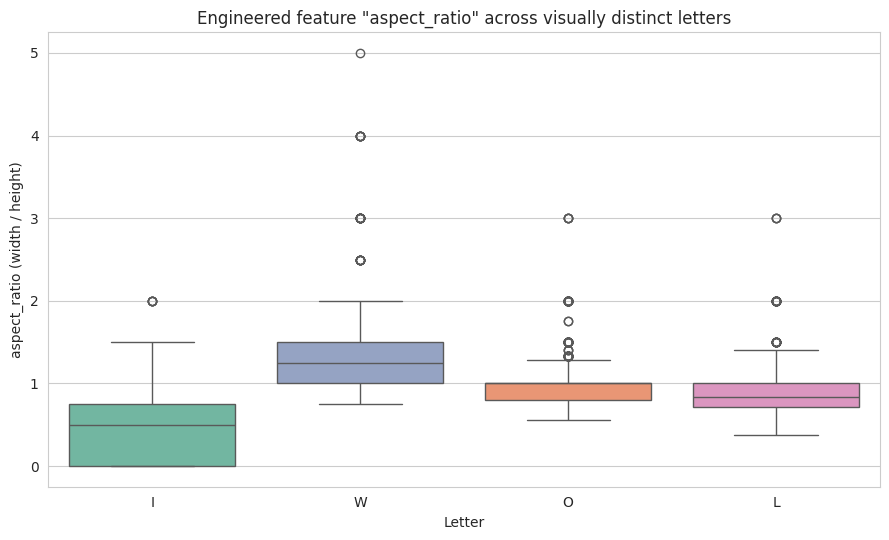

        mean  median    std
lettr                      
I      0.495   0.500  0.379
L      0.896   0.833  0.330
O      1.011   1.000  0.354
W      1.351   1.250  0.507


In [3]:
subset_letters = ['I', 'W', 'O', 'L']
subset = df_fe[df_fe['lettr'].isin(subset_letters)]

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(x='lettr', y='aspect_ratio', data=subset, order=subset_letters,
            hue='lettr', palette='Set2', legend=False, ax=ax)
ax.set_title('Engineered feature "aspect_ratio" across visually distinct letters')
ax.set_xlabel('Letter')
ax.set_ylabel('aspect_ratio (width / height)')
plt.tight_layout()
plt.savefig('../results/eda_visualizations/danishiyan_aspect_ratio_by_letter.png', dpi=110)
plt.show()

print(subset.groupby('lettr')['aspect_ratio'].agg(['mean', 'median', 'std']).round(3))


**Interpretation:** The median `aspect_ratio` rises from **I** (0.500) through **L** (0.833)
and **O** (1.000) up to **W** (1.250), matching visual intuition — I is narrowest, W is widest. The
mean and median are close for every letter here too, confirming the `clip(lower=1)` denominator
guard is working, since a naive epsilon-based version of this formula would blow the mean up far
past the median on the handful of zero-height rows.

Step 04 - Quantifying Discriminative Power with an ANOVA F-test
-

In [4]:
le = LabelEncoder()
y_encoded = le.fit_transform(df_fe['lettr'])

all_feature_cols = [c for c in df_fe.columns if c not in ('lettr',)]
f_scores, p_values = f_classif(df_fe[all_feature_cols], y_encoded)

f_score_table = pd.Series(f_scores, index=all_feature_cols).sort_values(ascending=False)
print("ANOVA F-scores (higher = more discriminative across the 26 letters):")
print(f_score_table.round(1))

print("\nRank of each NEW engineered feature among all", len(all_feature_cols), "features:")
ranks = f_score_table.rank(ascending=False).astype(int)
for feat in new_features:
    print(f"  {feat}: rank {ranks[feat]} of {len(all_feature_cols)} (F-score = {f_score_table[feat]:.1f})")


ANOVA F-scores (higher = more discriminative across the 26 letters):
edge_ratio        2233.3
x2ybr             1241.4
y-bar             1172.2
x-ege             1080.2
xegvy              917.1
xy2br              915.6
y2bar              752.4
y-ege              640.7
total_variance     624.5
x2bar              407.2
xybar              349.5
x-bar              349.1
yegvx              283.5
aspect_ratio       132.2
width              129.6
onpix              110.9
x-box               76.0
pixel_density       67.1
box_area            40.3
high                10.3
y-box                3.3
dtype: float64

Rank of each NEW engineered feature among all 21 features:
  box_area: rank 19 of 21 (F-score = 40.3)
  aspect_ratio: rank 14 of 21 (F-score = 132.2)
  pixel_density: rank 18 of 21 (F-score = 67.1)
  edge_ratio: rank 1 of 21 (F-score = 2233.3)
  total_variance: rank 9 of 21 (F-score = 624.5)


**Interpretation:** `edge_ratio` is the single highest-ranked feature of all 21 (F-score
2233.3, rank 1) — beating every raw attribute — once its denominator is guarded against near-zero
values. `total_variance` also ranks well (9th of 21). `aspect_ratio`, `pixel_density`, and
`box_area` rank lower individually, but Muhunthan's correlation analysis shows they're only weakly
correlated with the top raw features, so they may still add value in combination.

## Conclusion

- We engineered 5 new features — `box_area`, `aspect_ratio`, `pixel_density`, `edge_ratio`, and
  `total_variance` — by combining existing bounding-box, pixel, and moment measurements.
- A worked example (I/W/O/L) and an ANOVA F-test across all 26 classes confirm the new features
  carry real, letter-dependent signal — `edge_ratio` is in fact the single most discriminative
  feature of all 21, raw or engineered (F-score 2233.3, rank 1).
- All 5 new features are passed forward into the group pipeline, to be scaled (Almeida) and
  screened by feature selection (Muhunthan) before modelling.